# AuriSign FSL Phrase/Word Recognition — MediaPipe + 1D CNN

This notebook records **multi-frame sequences** of two-hand MediaPipe landmarks, trains a 1D CNN, and evaluates it on a held-out test set.

**Important:** Existing single-frame `.npy` files in the old `phrase_dataset` are not compatible with this temporal model. This notebook saves new sequences under `phrase_sequence_dataset` to avoid mixing old and new formats.

In [1]:
!pip install opencv-python mediapipe==0.10.14 matplotlib seaborn tensorflow scikit-learn tensorflowjs ipywidgets


[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [20]:
import cv2
import mediapipe as mp
import numpy as np
import os
from time import time


# Data collection: one labeled sample is a sequence of consecutive video frames.
# Each frame is represented by 128 features: left hand (63 xyz + handedness) and right hand (63 xyz + handedness).
# Missing hands are zero-padded. A short missing detection within a sequence carries forward the last valid frame.
# Press SPACE to start a 3-second countdown and record one full sequence; press q to skip the current class.

In [ ]:
PHRASE_CLASSES = [
    "Angry", "Book", "Bored", "Bye", "Eat", 
    "Help", "I Love You", "No", "Please", "Sorry",
    "Thank You", "Tired", "Unknown", "Water", "Yes"
]

NUM_CLASSES = len(PHRASE_CLASSES)
DATA_PATH = "phrase_sequence_dataset"  # separate folder: do not mix with legacy single-frame data
SEQ_LEN = 24
SAMPLES_PER_PHRASE = 100
CENTER_BY_WRIST = True
COUNTDOWN_SECONDS = 3

os.makedirs(DATA_PATH, exist_ok=True)
for phrase in PHRASE_CLASSES:
    os.makedirs(os.path.join(DATA_PATH, phrase), exist_ok=True)

mp_hands = mp.solutions.hands
mp_draw = mp.solutions.drawing_utils
hands = mp_hands.Hands(
    static_image_mode=False,
    max_num_hands=2,
    min_detection_confidence=0.7,
    min_tracking_confidence=0.7
)

def extract_two_hand_keypoints(result):
    left_pts = np.zeros(64, dtype=np.float32)
    right_pts = np.zeros(64, dtype=np.float32)
    if result.multi_hand_landmarks:
        for lm, hd in zip(result.multi_hand_landmarks, result.multi_handedness):
            label = hd.classification[0].label
            pts = np.array([[p.x, p.y, p.z] for p in lm.landmark], dtype=np.float32)
            if CENTER_BY_WRIST:
                pts -= pts[0]
            pts_flat = np.append(pts.flatten(), 0.0 if label == "Left" else 1.0)
            if label == "Left":
                left_pts = pts_flat
            else:
                right_pts = pts_flat
    return np.concatenate([left_pts, right_pts]).astype(np.float32)

def record_phrase_sequence(cap, phrase, sample_index):
    sequence = []
    countdown_start = None
    recording = False
    while True:
        ret, frame = cap.read()
        if not ret:
            continue
        frame = cv2.flip(frame, 1)
        result = hands.process(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        if result.multi_hand_landmarks:
            for lm in result.multi_hand_landmarks:
                mp_draw.draw_landmarks(frame, lm, mp_hands.HAND_CONNECTIONS)

        key = cv2.waitKey(1) & 0xFF
        now = time()
        if key == ord("q"):
            return None, True
        if key == ord(" ") and countdown_start is None and not recording:
            countdown_start = now
        if countdown_start is not None and now - countdown_start >= COUNTDOWN_SECONDS:
            recording = True
            countdown_start = None
            sequence = []

        if recording:
            features = extract_two_hand_keypoints(result)
            if not result.multi_hand_landmarks and sequence:
                features = sequence[-1].copy()
            sequence.append(features)
            cv2.putText(frame, f"RECORDING {len(sequence)}/{SEQ_LEN}", (10, 35),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
            if len(sequence) >= SEQ_LEN:
                return np.asarray(sequence, dtype=np.float32), False
        elif countdown_start is not None:
            remaining = max(0, COUNTDOWN_SECONDS - (now - countdown_start))
            cv2.putText(frame, f"Starting in {int(remaining)+1}", (10, 35),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)

        cv2.putText(frame, f"{phrase} | sample {sample_index+1}/{SAMPLES_PER_PHRASE}", (10, 70),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
        cv2.putText(frame, "SPACE: countdown and record | q: skip class", (10, frame.shape[0]-15),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1)
        cv2.imshow("Record FSL Phrase Sequence", frame)

cap = cv2.VideoCapture(0)
if not cap.isOpened():
    raise RuntimeError("Could not open camera. Check CAMERA_INDEX or camera permissions.")

try:
    for phrase in PHRASE_CLASSES:
        folder = os.path.join(DATA_PATH, phrase)
        existing = [int(os.path.splitext(f)[0]) for f in os.listdir(folder)
                    if f.endswith(".npy") and os.path.splitext(f)[0].isdigit()]
        count = max(existing, default=-1) + 1
        target = SAMPLES_PER_PHRASE
        print(f"\nClass: {phrase}. Existing samples: {count}. Target total: {target}")
        while count < target:
            seq, skip_class = record_phrase_sequence(cap, phrase, count)
            if skip_class:
                break
            if seq is None or seq.shape != (SEQ_LEN, 128):
                print("Sequence not saved: invalid shape.")
                continue
            np.save(os.path.join(folder, f"{count:04d}.npy"), seq)
            count += 1
            print(f"Saved {phrase}: {count}/{target}")
finally:
    cap.release()
    hands.close()
    cv2.destroyAllWindows()

print("Phrase sequence data collection complete.")


# Data Splitting and Preprocessing

Each `.npy` sample must have shape `(SEQ_LEN, 128)`. The test set is held out and is not used for training or model selection.

In [25]:
# Landmark normalization: wrist-relative position is already applied during collection.
# This second step normalizes scale using wrist-to-middle-MCP distance per hand/frame.
# Keep this exact transform consistent for training, validation, test, and live inference.
def normalize_landmark_sequences(X, hand_feature_width=64):
    """Scale-normalize wrist-centered MediaPipe xyz coordinates per hand/frame.

    Each hand's xyz coordinates are divided by its wrist-to-middle-MCP distance
    (landmark 0 to landmark 9). The handedness feature at index 63 is preserved.
    Zero-padded/missing hands remain zero. Input shape: (samples, frames, features).
    """
    X = np.asarray(X, dtype=np.float32).copy()
    for start in range(0, X.shape[-1], hand_feature_width):
        block_end = min(start + hand_feature_width, X.shape[-1])
        xyz_end = min(start + 63, block_end)
        if xyz_end - start < 30:
            continue
        xyz = X[..., start:xyz_end].reshape(*X.shape[:-1], -1, 3)
        # Wrist is already at/near (0, 0, 0) after wrist-centering.
        # Landmark 9 (middle-finger MCP) is xyz index 27:30.
        palm_scale = np.linalg.norm(xyz[..., 9, :], axis=-1, keepdims=True)
        valid_hand = palm_scale > 1e-6
        safe_scale = np.where(valid_hand, palm_scale, 1.0)
        normalized_xyz = xyz / safe_scale[..., None]
        normalized_xyz = np.where(valid_hand[..., None], normalized_xyz, 0.0)
        X[..., start:xyz_end] = normalized_xyz.reshape(*X.shape[:-1], -1)
    return X


In [26]:
import os
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

X, y_indices = [], []
for i, phrase in enumerate(PHRASE_CLASSES):
    folder = os.path.join(DATA_PATH, phrase)
    files = sorted(f for f in os.listdir(folder) if f.endswith(".npy"))
    if not files:
        raise ValueError(f"No sequence samples for {phrase}. Run the data collection cell.")
    for filename in files:
        sample = np.load(os.path.join(folder, filename), allow_pickle=False)
        if sample.shape != (SEQ_LEN, 128) or not np.isfinite(sample).all():
            raise ValueError(f"Invalid sample {phrase}/{filename}: shape={sample.shape}; expected {(SEQ_LEN, 128)}")
        X.append(sample)
        y_indices.append(i)

X = np.asarray(X, dtype=np.float32)
y_indices = np.asarray(y_indices, dtype=np.int64)
X = normalize_landmark_sequences(X, hand_feature_width=64)
counts = np.bincount(y_indices, minlength=len(PHRASE_CLASSES))
print("Samples per class:", dict(zip(PHRASE_CLASSES, counts.tolist())))
if counts.min() < 5:
    raise ValueError("Each class needs at least 5 samples for a stratified train/validation/test split; more is strongly recommended.")

# 20% test; from remaining 80%, reserve 20% for validation -> 64/16/20 overall.
X_trainval, X_test_seq, y_trainval, y_test_idx = train_test_split(
    X, y_indices, test_size=0.20, random_state=42, stratify=y_indices
)
X_train_seq, X_val_seq, y_train_idx, y_val_idx = train_test_split(
    X_trainval, y_trainval, test_size=0.20, random_state=42, stratify=y_trainval
)
print("Input shape:", X.shape)
print("Train:", X_train_seq.shape, "Validation:", X_val_seq.shape, "Test:", X_test_seq.shape)
print("NOTE: If samples from the same recording session/person are highly similar, use a group-wise split by session/person for stronger generalization evidence.")


Samples per class: {'Angry': 100, 'Book': 100, 'Bored': 100, 'Bye': 100, 'Eat': 100, 'Help': 100, 'I Love You': 100, 'No': 100, 'Please': 100, 'Sorry': 100, 'Thank You': 100, 'Tired': 100, 'Unknown': 100, 'Water': 100, 'Yes': 100}
Input shape: (1500, 24, 128)
Train: (960, 24, 128) Validation: (240, 24, 128) Test: (300, 24, 128)
NOTE: If samples from the same recording session/person are highly similar, use a group-wise split by session/person for stronger generalization evidence.


# Build a 1D CNN over the temporal axis.
# Input shape: (24 frames, 128 features per frame).

In [27]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(SEQ_LEN, 128)),
    tf.keras.layers.Conv1D(64, kernel_size=3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv1D(96, kernel_size=3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling1D(pool_size=2),
    tf.keras.layers.Conv1D(128, kernel_size=3, padding="same", activation="relu"),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.35),
    tf.keras.layers.Dense(len(PHRASE_CLASSES), activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_3 (Conv1D)               │ (None, 24, 64)         │        24,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 24, 96)         │        18,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 96)         │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 12, 96)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 12, 128)        │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,247 (387.68 KB)

 Trainable params: 98,927 (386.43 KB)

 Non-trainable params: 320 (1.25 KB)

# Training

Validation data is used for early stopping and model selection. The held-out test set is used only for final evaluation.

In [28]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=10, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "phrase_1dcnn_best.keras", monitor="val_loss",
        save_best_only=True, verbose=1
    )
]

history = model.fit(
    X_train_seq, y_train_idx,
    validation_data=(X_val_seq, y_val_idx),
    epochs=100,
    batch_size=16,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)


Epoch 1/100
48/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3732 - loss: 2.0868
Epoch 1: val_loss improved from None to 1.87436, saving model to phrase_1dcnn_best.keras

Epoch 1: finished saving model to phrase_1dcnn_best.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.5531 - loss: 1.4978 - val_accuracy: 0.5083 - val_loss: 1.8744 - learning_rate: 0.0010
Epoch 2/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8065 - loss: 0.6697
Epoch 2: val_loss improved from 1.87436 to 0.97900, saving model to phrase_1dcnn_best.keras

Epoch 2: finished saving model to phrase_1dcnn_best.keras
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8292 - loss: 0.5856 - val_accuracy: 0.7875 - val_loss: 0.9790 - learning_rate: 0.0010
Epoch 3/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9165 - loss: 0.3193
Epoch 3: val_loss improved from 0.97900 to 0.62079, saving model to phrase_1dcnn_best.keras

Epoch 3: finished saving model to phrase_1dcnn_best.keras
60/60 ━━━━━━━━━━━

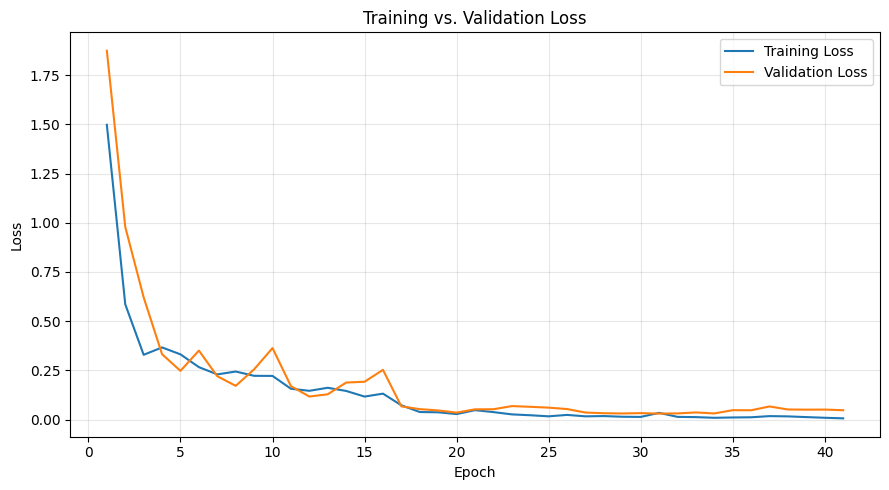

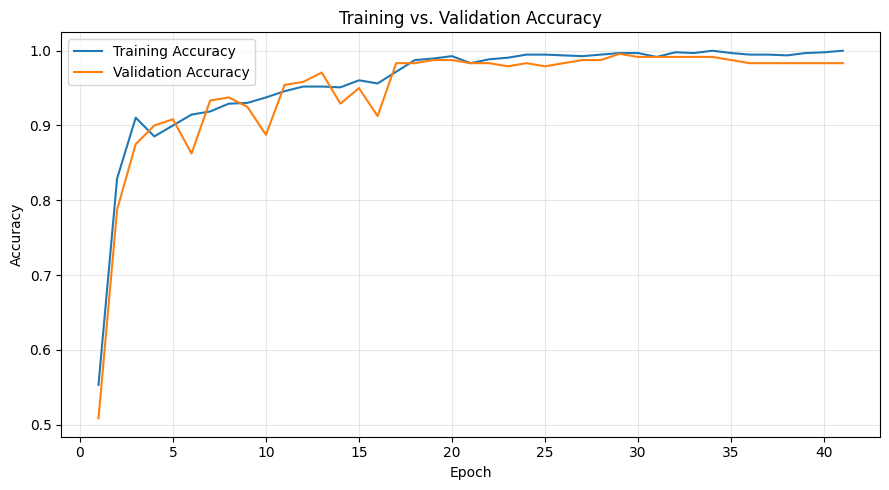

In [29]:
import matplotlib.pyplot as plt

# Use the History object returned by TensorFlow/Keras model.fit()
history_data = history.history

epochs = range(1, len(history_data["loss"]) + 1)

# 1. Loss curve — useful for diagnosing overfitting/underfitting
plt.figure(figsize=(9, 5))
plt.plot(epochs, history_data["loss"], label="Training Loss")
plt.plot(epochs, history_data["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs. Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Accuracy curve
if "accuracy" in history_data and "val_accuracy" in history_data:
    plt.figure(figsize=(9, 5))
    plt.plot(epochs, history_data["accuracy"], label="Training Accuracy")
    plt.plot(epochs, history_data["val_accuracy"], label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Training vs. Validation Accuracy")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

=== HELD-OUT TEST METRICS ===
Test samples       : 300
Accuracy           : 0.9767
Macro precision    : 0.9781
Macro recall       : 0.9767
Macro F1-score     : 0.9768
Weighted precision : 0.9781
Weighted recall    : 0.9767
Weighted F1-score  : 0.9768
\nPer-class classification report:
              precision    recall  f1-score   support

       Angry     1.0000    1.0000    1.0000        20
        Book     1.0000    0.9000    0.9474        20
       Bored     0.9524    1.0000    0.9756        20
         Bye     0.9524    1.0000    0.9756        20
         Eat     0.9500    0.9500    0.9500        20
        Help     1.0000    0.9500    0.9744        20
  I Love You     1.0000    1.0000    1.0000        20
          No     1.0000    1.0000    1.0000        20
      Please     1.0000    1.0000    1.0000        20
       Sorry     1.0000    0.9500    0.9744        20
   Thank You     1.0000    0.9500    0.9744        20
       Tired     1.0000    1.0000    1.0000        20
     Unknow

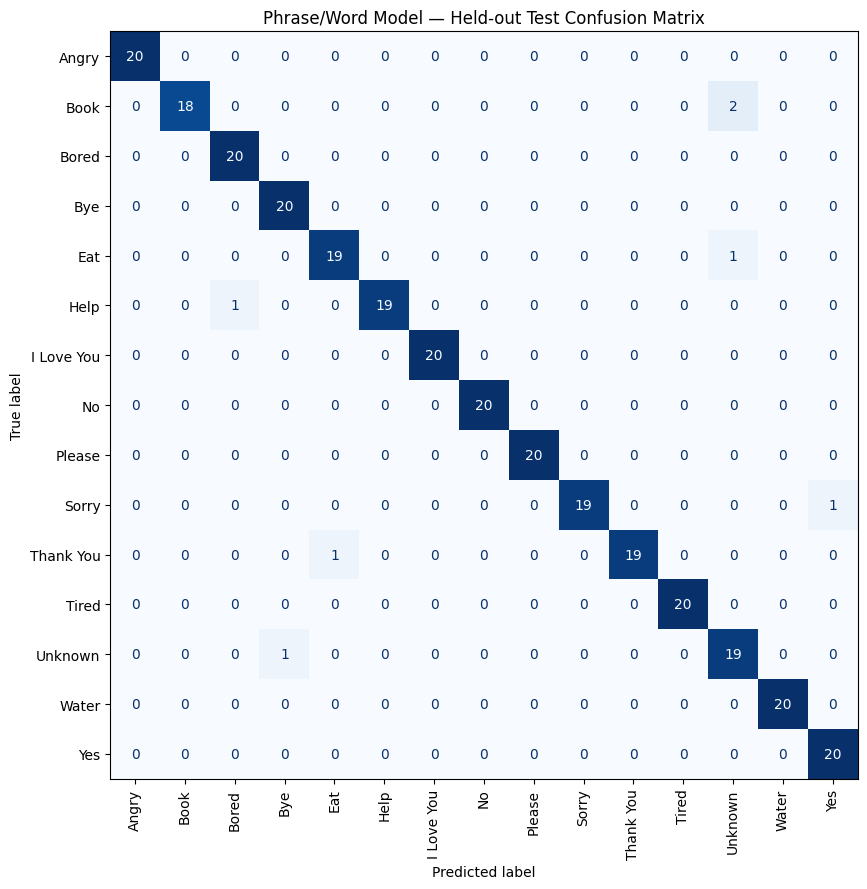

\n=== MODEL-ONLY INFERENCE TIME ===
Mean latency       : 9.031 ms
Median latency     : 8.586 ms
95th percentile    : 10.980 ms
Minimum latency    : 8.279 ms
Maximum latency    : 13.683 ms
Timing excludes camera capture and MediaPipe landmark extraction.


In [30]:
# Held-out test evaluation: accuracy, precision, recall, F1-score, confusion matrix, and inference time.
import time
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

# Warm-up model calls
_ = model(X_test_seq[:1], training=False)
for _ in range(5):
    _ = model(X_test_seq[:1], training=False)

probabilities = np.asarray(model.predict(X_test_seq, verbose=0))
y_pred_idx = np.argmax(probabilities, axis=1)
y_true_idx = y_test_idx

print("=== HELD-OUT TEST METRICS ===")
print(f"Test samples       : {len(y_true_idx)}")
print(f"Accuracy           : {accuracy_score(y_true_idx, y_pred_idx):.4f}")
print(f"Macro precision    : {precision_score(y_true_idx, y_pred_idx, average='macro', zero_division=0):.4f}")
print(f"Macro recall       : {recall_score(y_true_idx, y_pred_idx, average='macro', zero_division=0):.4f}")
print(f"Macro F1-score     : {f1_score(y_true_idx, y_pred_idx, average='macro', zero_division=0):.4f}")
print(f"Weighted precision : {precision_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0):.4f}")
print(f"Weighted recall    : {recall_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0):.4f}")
print(f"Weighted F1-score  : {f1_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0):.4f}")
print("\\nPer-class classification report:")
print(classification_report(
    y_true_idx, y_pred_idx, labels=np.arange(len(PHRASE_CLASSES)),
    target_names=PHRASE_CLASSES, digits=4, zero_division=0
))

cm = confusion_matrix(y_true_idx, y_pred_idx, labels=np.arange(len(PHRASE_CLASSES)))
fig, ax = plt.subplots(figsize=(max(12, len(PHRASE_CLASSES)*0.5), max(9, len(PHRASE_CLASSES)*0.45)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=PHRASE_CLASSES)
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Phrase/Word Model — Held-out Test Confusion Matrix")
plt.tight_layout()
plt.show()

# Single-sample model-only inference time (preprocessed 24-frame sequence -> prediction).
latency_ms = []
for sample in X_test_seq:
    start = time.perf_counter()
    _ = model(sample[np.newaxis, ...], training=False)
    latency_ms.append((time.perf_counter() - start) * 1000.0)
latency_ms = np.asarray(latency_ms)

print("\\n=== MODEL-ONLY INFERENCE TIME ===")
print(f"Mean latency       : {latency_ms.mean():.3f} ms")
print(f"Median latency     : {np.percentile(latency_ms, 50):.3f} ms")
print(f"95th percentile    : {np.percentile(latency_ms, 95):.3f} ms")
print(f"Minimum latency    : {latency_ms.min():.3f} ms")
print(f"Maximum latency    : {latency_ms.max():.3f} ms")
print("Timing excludes camera capture and MediaPipe landmark extraction.")


## Model Export

Export the trained temporal 1D CNN. Keep the class order aligned with `PHRASE_CLASSES` wherever the model is integrated into AuriSign.

In [31]:
# Export the trained Keras model and the ordered label list.
import json
model.save("phrase_1dcnn_model.keras")
model.export("phrase_1dcnn_saved_model")

with open("phrase_1dcnn_labels.json", "w", encoding="utf-8") as f:
    json.dump(PHRASE_CLASSES, f, ensure_ascii=False, indent=2)

print("Saved phrase 1D CNN model and class labels.")

INFO:tensorflow:Assets written to: phrase_1dcnn_saved_model/assets


INFO:tensorflow:Assets written to: phrase_1dcnn_saved_model/assets


Saved artifact at 'phrase_1dcnn_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 24, 128), dtype=tf.float32, name='keras_tensor_11')
Output Type:
  TensorSpec(shape=(None, 15), dtype=tf.float32, name=None)
Captures:
  133974010736912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133974006846032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133974006844304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133974006848720: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133974006849104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133974006846800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133974006845648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133974006847760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133974006848912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133974006850256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133974

## Live Camera Testing — Required Sequence Update

The previous live-camera cells classified a single frame at a time. They are intentionally removed because they do not match this temporal 1D CNN's required input shape `(24, 128)`. A valid live test must buffer 24 consecutive MediaPipe landmark vectors, apply the same two-hand ordering and wrist-centering used during collection, then submit the full sequence to the model. Record model-only inference latency separately from end-to-end frame-processing time. Do not treat a single frame's prediction as a phrase/word prediction for this model.

**Normalization requirement:** Before live inference, apply `normalize_landmark_sequences` to the buffered 24-frame sequence using the same 64-feature hand blocks. Do not normalize only during training.
